# Solar Energy Output: Weather-Driven Prediction and Forecast Validation

**Question:** how well can the energy captured by a solar installation be predicted from weather conditions, and how much of that skill survives when the model has to predict a year it has never seen?

The data is **simulated** by `src/generate_data.py`: a small photovoltaic plant in central Europe, one reading every 15 minutes from **2017 to mid-2022** (≈197,000 rows), with
energy captured (Wh, the target), sunlight intensity, temperature, one-hour rainfall, cloud coverage and length of daylight. Typical data-quality problems are planted on purpose (text in numeric cells, impossible values) so the cleaning steps are tested.

Steps: data quality checks, exploratory analysis, preprocessing, linear regression vs random forest, and two validation schemes:

* a **random 80/20 split**, the usual textbook setup, and
* a **chronological split** (train 2017–2021, test 2022), which is how the model would actually be used.

Run top to bottom, locally or in Google Colab (the data is read straight from this GitHub repository if the local copy is missing).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)
os.makedirs("../reports/figures", exist_ok=True)

TARGET = "Energy Captured[Wh]"
WEATHER = ["Sun Light Intensity (W/m2)", "Temperature", "1 Hour Rain Fall", "Cloud Coverage", "Length of Day_Light"]

## 1. Load the data

In [2]:
LOCAL_PATH = "../data/solar_weather.csv.gz"
REMOTE_PATH = ("https://raw.githubusercontent.com/mohammedelsayed741996-blip/"
               "solar-energy-forecasting/main/data/solar_weather.csv.gz")

# keep_default_na=False so text entries such as "n/a" arrive as text and are counted below
raw = pd.read_csv(LOCAL_PATH if os.path.exists(LOCAL_PATH) else REMOTE_PATH, keep_default_na=False, low_memory=False)
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head()

197,088 rows x 7 columns


,Time,Energy Captured[Wh],Sun Light Intensity (W/m2),Temperature,1 Hour Rain Fall,Cloud Coverage,Length of Day_Light
0,2017-01-01 00:00:00,0.0,0.0,-1.8,0.0,72,457
1,2017-01-01 00:15:00,0.0,0.0,-1.8,0.0,72,457
2,2017-01-01 00:30:00,0.0,0.0,-1.8,0.0,72,457
3,2017-01-01 00:45:00,0.0,0.0,-1.8,0.0,72,457
4,2017-01-01 01:00:00,0.0,0.0,-2.9,0.0,69,457


## 2. Data quality

Several numeric columns are stored as text because a few cells hold non-numeric entries. Each column is converted explicitly and the number of values that could not be parsed is reported, instead of silently turning them into missing values.

In [3]:
df = raw.copy()
df["Time"] = pd.to_datetime(df["Time"], errors="coerce")
quality = []
for col in [TARGET] + WEATHER:
    before = df[col].notna().sum()
    df[col] = pd.to_numeric(df[col], errors="coerce")
    quality.append({"column": col, "missing_or_unparseable": int(len(df) - df[col].notna().sum()),
                    "text_values_dropped": int(before - df[col].notna().sum())})
quality = pd.DataFrame(quality)
print("Unparseable timestamps:", int(df["Time"].isna().sum()))
print("Duplicated timestamps:", int(df["Time"].duplicated().sum()))
quality

Unparseable timestamps: 0
Duplicated timestamps: 0


,column,missing_or_unparseable,text_values_dropped
0,Energy Captured[Wh],4,4
1,Sun Light Intensity (W/m2),7,7
2,Temperature,6,6
3,1 Hour Rain Fall,4,4
4,Cloud Coverage,13,13
5,Length of Day_Light,5,5


In [4]:
df[[TARGET] + WEATHER].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Energy Captured[Wh],197084.0,662.47,1087.31,-48.0,0.0,0.0,966.0,5020.00
Sun Light Intensity (W/m2),197081.0,40.43,59.69,0.0,0.0,2.7,63.9,259.50
Temperature,197082.0,9.67,7.44,-5.3,3.7,9.6,15.5,25.80
1 Hour Rain Fall,197084.0,0.02,0.08,0.0,0.0,0.0,0.0,1.45
Cloud Coverage,197075.0,56.87,28.82,-250.0,32.0,61.0,83.0,100.00
Length of Day_Light,197083.0,727.32,185.63,450.0,548.0,732.0,909.0,990.00


Physically impossible values: cloud coverage is a percentage (0–100) and energy captured cannot be negative. Out-of-range readings are treated as sensor errors, set to missing and then filled by time interpolation together with the unparseable cells.

In [5]:
impossible = {
    "Cloud Coverage outside 0-100": int(((df["Cloud Coverage"] < 0) | (df["Cloud Coverage"] > 100)).sum()),
    "Negative energy": int((df[TARGET] < 0).sum()),
}
print(impossible)
df.loc[(df["Cloud Coverage"] < 0) | (df["Cloud Coverage"] > 100), "Cloud Coverage"] = np.nan
df.loc[df[TARGET] < 0, TARGET] = np.nan

df = df.dropna(subset=["Time"]).sort_values("Time").set_index("Time")
df[[TARGET] + WEATHER] = df[[TARGET] + WEATHER].interpolate(method="time", limit_direction="both")
print("Missing values after cleaning:", int(df.isna().sum().sum()))
print("Period covered:", df.index.min(), "to", df.index.max())
print("Median interval between readings:", df.index.to_series().diff().median())

{'Cloud Coverage outside 0-100': 6, 'Negative energy': 25}
Missing values after cleaning: 0
Period covered: 2017-01-01 00:00:00 to 2022-08-15 23:45:00
Median interval between readings: 0 days 00:15:00


## 3. Exploratory analysis

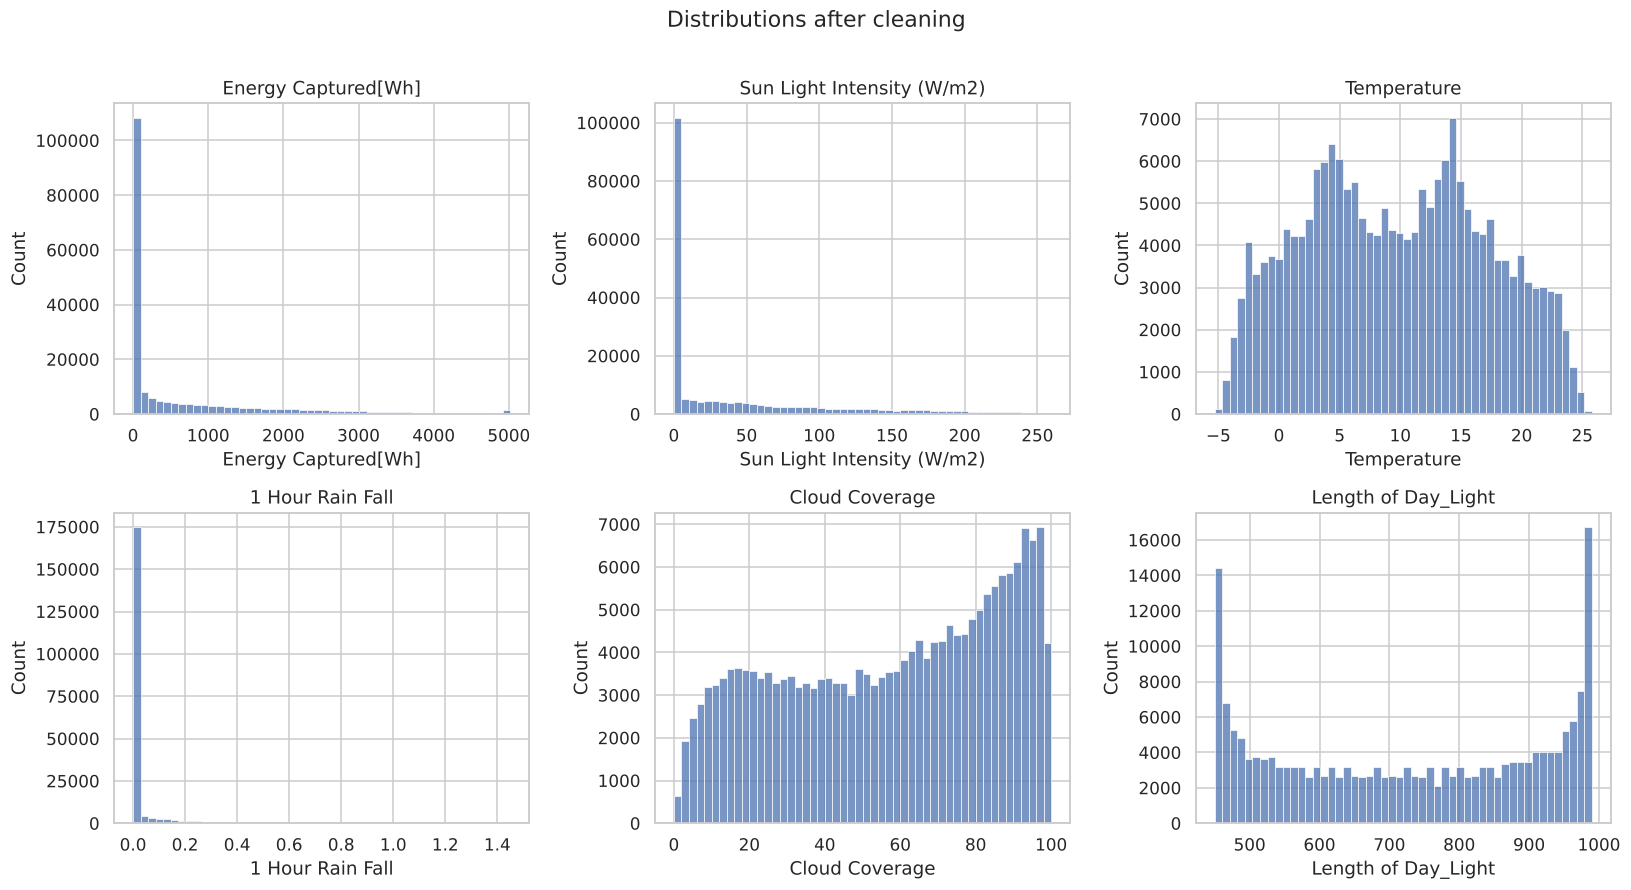

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), [TARGET] + WEATHER):
    sns.histplot(df[col], bins=50, ax=ax)
    ax.set_title(col)
plt.suptitle("Distributions after cleaning", y=1.01)
plt.tight_layout()
plt.savefig("../reports/figures/distributions.png", dpi=120)

Energy is zero for most readings (night), so its distribution is heavily skewed. Means alone would mislead. The daily and seasonal profiles below show where the energy actually comes from.

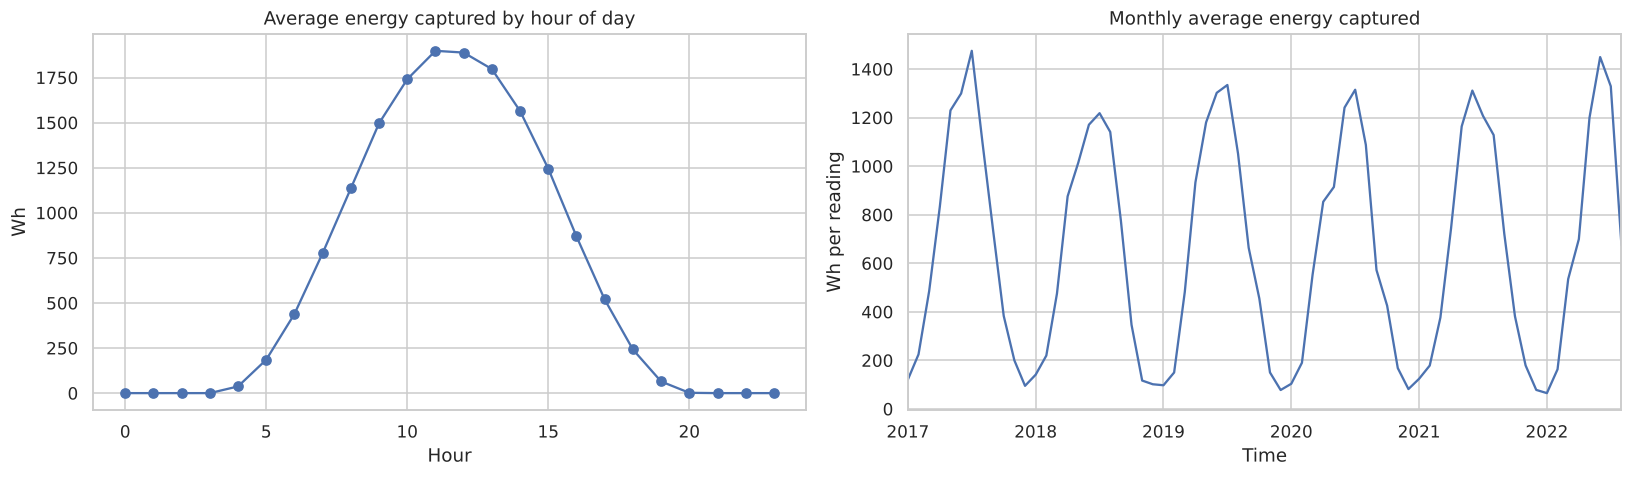

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
df.groupby(df.index.hour)[TARGET].mean().plot(ax=axes[0], marker="o")
axes[0].set_title("Average energy captured by hour of day"); axes[0].set_xlabel("Hour"); axes[0].set_ylabel("Wh")
monthly = df[TARGET].resample("MS").mean()
monthly.plot(ax=axes[1])
axes[1].set_title("Monthly average energy captured"); axes[1].set_ylabel("Wh per reading")
plt.tight_layout()
plt.savefig("../reports/figures/daily_and_seasonal_profile.png", dpi=120)

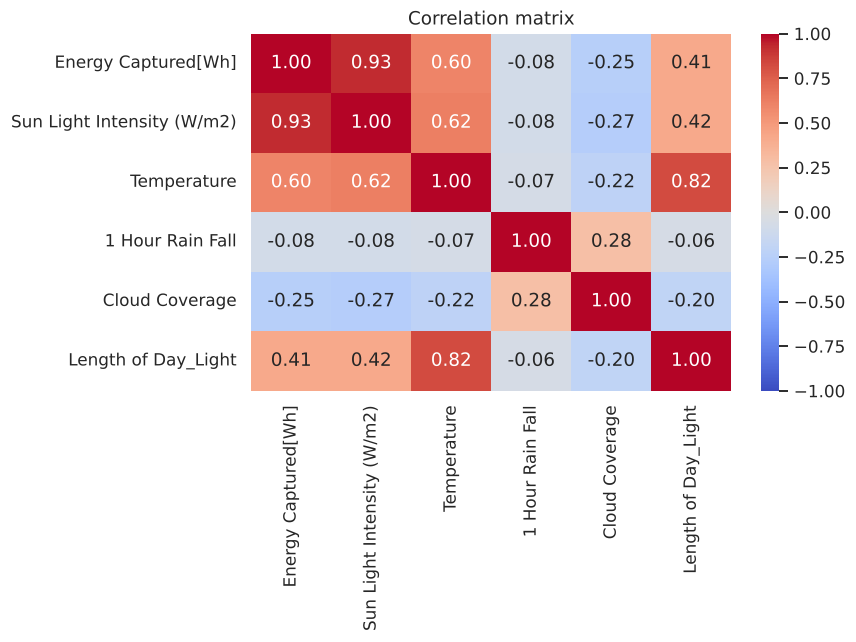

In [8]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[[TARGET] + WEATHER].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix")
plt.tight_layout()
plt.savefig("../reports/figures/correlation_heatmap.png", dpi=120)

## 4. Models

Features: the five weather variables. Target: energy captured per reading. Two models: linear regression (baseline) and a random forest (non-linear).

In [9]:
def evaluate(model, X_tr, y_tr, X_te, y_te):
    model.fit(X_tr, y_tr)
    pred = np.clip(model.predict(X_te), 0, None)
    return pred, {"R2": r2_score(y_te, pred), "MAE (Wh)": mean_absolute_error(y_te, pred),
                  "RMSE (Wh)": mean_squared_error(y_te, pred) ** 0.5}

def models():
    return {"Linear regression": LinearRegression(),
            "Random forest": RandomForestRegressor(n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=SEED)}

X, y = df[WEATHER], df[TARGET]

### 4a. Random 80/20 split

Neighbouring 15-minute readings share the same hourly weather values, so a random split puts near-copies of each test row into the training set. These scores can be optimistic, and the chronological split below is the check.

In [10]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=SEED)
results, random_preds = [], {}
for name, model in models().items():
    pred, scores = evaluate(model, X_tr, y_tr, X_te, y_te)
    random_preds[name] = pred
    results.append({"split": "Random 80/20", "model": name, **scores})
pd.DataFrame(results).round(3)

,split,model,R2,MAE (Wh),RMSE (Wh)
0,Random 80/20,Linear regression,0.858,197.377,409.247
1,Random 80/20,Random forest,0.860,187.989,405.670


### 4b. Chronological split: train 2017–2021, test 2022

The model only sees the past and is scored on a full unseen year, the way it would be deployed.

In [11]:
train_mask = df.index.year <= 2021
test_mask = df.index.year == 2022
print(f"Train: {train_mask.sum():,} readings | Test (2022): {test_mask.sum():,} readings")
time_preds = {}
for name, model in models().items():
    pred, scores = evaluate(model, X[train_mask], y[train_mask], X[test_mask], y[test_mask])
    time_preds[name] = pred
    results.append({"split": "Chronological (test = 2022)", "model": name, **scores})
results_df = pd.DataFrame(results).round(3)
results_df.to_csv("../reports/model_results.csv", index=False)
results_df

Train: 175,296 readings | Test (2022): 21,792 readings


,split,model,R2,MAE (Wh),RMSE (Wh)
0,Random 80/20,Linear regression,0.858,197.377,409.247
1,Random 80/20,Random forest,0.860,187.989,405.670
2,Chronological (test = 2022),Linear regression,0.870,216.101,427.109
3,Chronological (test = 2022),Random forest,0.866,211.655,434.447


**Reading the comparison.** Error in Wh (MAE, RMSE) is the fair yardstick across the two schemes, because R² also depends on how variable each test set is (the 2022 test year runs January to mid-August, so it is summer-heavy). On the unseen year the error rises: the model has never seen the panels at their 2022 age. The random forest adds little over linear regression, because energy is close to proportional to sunlight intensity. What remains unexplained (passing clouds within the hour, soiling, snow, outages) is not in the weather columns at all.

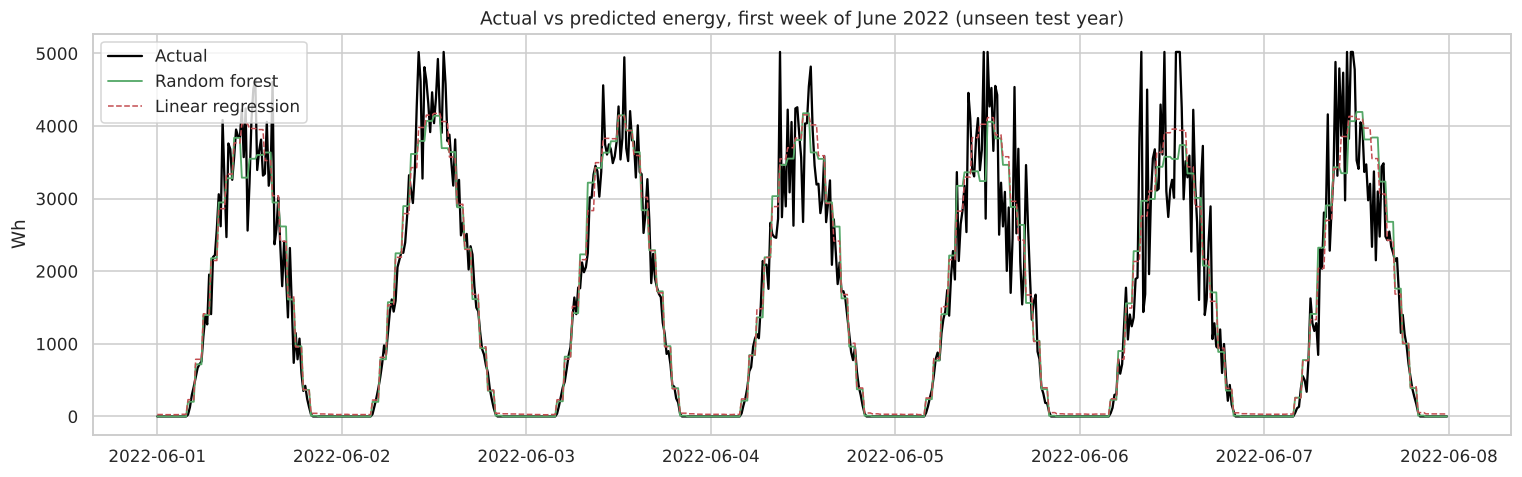

In [12]:
week = df[test_mask].index[(df[test_mask].index >= "2022-06-01") & (df[test_mask].index < "2022-06-08")]
pos = df[test_mask].index.get_indexer(week)
plt.figure(figsize=(14, 4.5))
plt.plot(week, y[test_mask].iloc[pos], label="Actual", color="black", lw=1.5)
plt.plot(week, time_preds["Random forest"][pos], label="Random forest", color="#55A868", lw=1.2)
plt.plot(week, time_preds["Linear regression"][pos], label="Linear regression", color="#C44E52", lw=1, ls="--")
plt.title("Actual vs predicted energy, first week of June 2022 (unseen test year)")
plt.ylabel("Wh"); plt.legend()
plt.tight_layout()
plt.savefig("../reports/figures/actual_vs_predicted_week.png", dpi=120)

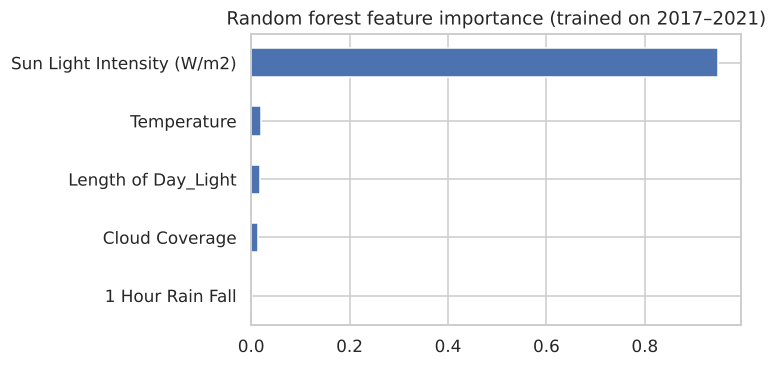

In [13]:
rf = RandomForestRegressor(n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=SEED).fit(X[train_mask], y[train_mask])
importance = pd.Series(rf.feature_importances_, index=WEATHER).sort_values()
importance.plot.barh(figsize=(7, 3.5), color="#4C72B0")
plt.title("Random forest feature importance (trained on 2017–2021)")
plt.tight_layout()
plt.savefig("../reports/figures/feature_importance.png", dpi=120)

## 5. January: observed history and a weather-scenario estimate

The table uses the **observed** average energy per reading in each January in the data. The estimate for a future January is a **scenario**, not a weather forecast: the random forest (trained on 2017–2021) is fed the weather of every past January, and the spread across those years gives a plausible range.

In [14]:
jan = df[df.index.month == 1]
jan_actual = jan.groupby(jan.index.year)[TARGET].mean().rename("observed_mean_Wh")
jan_model = pd.Series({yr: rf.predict(g[WEATHER]).clip(0).mean() for yr, g in jan.groupby(jan.index.year)},
                      name="model_mean_Wh")
jan_table = pd.concat([jan_actual, jan_model], axis=1).round(1)
jan_table.index.name = "January of"
jan_table

,observed_mean_Wh,model_mean_Wh
January of,,
2017,120.8,121.9
2018,140.9,133.2
2019,97.5,98.9
2020,103.6,106.0
2021,124.0,128.7
2022,65.1,79.3


In [15]:
scenario = jan_model.agg(["min", "median", "max"]).round(1)
print("Future January, average energy per reading under past January weather (Wh):")
print(f"  low {scenario['min']} | central {scenario['median']} | high {scenario['max']}")
print(f"Observed January 2022 average: {jan_actual.get(2022, float('nan')):.1f} Wh")

Future January, average energy per reading under past January weather (Wh):
  low 79.3 | central 114.0 | high 133.2
Observed January 2022 average: 65.1 Wh


The model over-estimates January 2022, the only January it did not train on. That fits slow panel ageing, which no weather variable captures: a production forecast should add a time trend or be retrained regularly.

## 6. Results summary

In [16]:
best_random = results_df[results_df["split"] == "Random 80/20"].sort_values("R2").iloc[-1]
best_time = results_df[results_df["split"] != "Random 80/20"].sort_values("R2").iloc[-1]
summary = pd.DataFrame({"item": ["Readings", "Period", f"Best model, random split ({best_random['model']})",
                                 f"Best model, test year 2022 ({best_time['model']})", "Top feature"],
                        "value": [f"{len(df):,}", f"{df.index.min():%Y-%m} to {df.index.max():%Y-%m}",
                                  f"R² {best_random['R2']:.3f}, MAE {best_random['MAE (Wh)']:.0f} Wh",
                                  f"R² {best_time['R2']:.3f}, MAE {best_time['MAE (Wh)']:.0f} Wh",
                                  importance.index[-1]]})
summary.to_csv("../reports/results_summary.csv", index=False)
summary

,item,value
0,Readings,"197,088"
1,Period,2017-01 to 2022-08
2,"Best model, random split (Random forest)","R² 0.860, MAE 188 Wh"
3,"Best model, test year 2022 (Linear regression)","R² 0.870, MAE 216 Wh"
4,Top feature,Sun Light Intensity (W/m2)
